<a href="https://colab.research.google.com/github/nielitropar/computer-vision/blob/main/Inside_the_CNN_(Not_a_Black_Box).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inside the CNN (Not a Black Box)

**Instructor:** Anita Budhiraja, Scientist-E, NIELIT Ropar

---

## Learning Objectives

By the end of this lecture, you will be able to:

- Explain **what CNNs actually learn** at each layer
- **Visualize feature maps** extracted by a real CNN (ResNet-18)
- Apply **Grad-CAM** to generate attention heatmaps
- Perform **failure analysis** — understand *why* a model gets things wrong
- Distinguish between correct reasoning and spurious reasoning

---

## Quick Recap (5 min)

From the previous lectures:

| Concept | Summary |
|---|---|
| **Image = Tensor** | A 224×224 RGB image is a tensor of shape `(3, 224, 224)` |
| **Convolution** | A sliding kernel that extracts local spatial features |
| **CNN** | Stacked conv layers that learn a feature hierarchy automatically |
| **Transfer Learning** | Reusing pretrained weights (e.g. ResNet) on new tasks |

Today's question: **What does the model actually see?**

---

## Setup & Installation

In [1]:
# Install required libraries
!pip install grad-cam opencv-python matplotlib torchvision -q

import torch
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import torch.nn as nn
import torch.nn.functional as F

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import urllib.request
from PIL import Image
import json
import warnings
warnings.filterwarnings('ignore')

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Setup complete! Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 71.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Setup complete! Using device: cuda
PyTorch version: 2.10.0+cu128


In [2]:
import requests
import json
from pathlib import Path

print("Downloading assets...")

# Define base directory explicitly
BASE_DIR = Path.cwd() / ""
BASE_DIR.mkdir(parents=True, exist_ok=True)

def download(url, filename):
    r = requests.get(url, timeout=10)
    r.raise_for_status()
    with open(filename, "wb") as f:
        f.write(r.content)

# Downloads now go to /content (Colab)
download("https://raw.githubusercontent.com/nielitropar/computer-vision/refs/heads/main/assets/Anita_Budhiraja.jpg", BASE_DIR / "person.jpg")
download("https://raw.githubusercontent.com/nielitropar/computer-vision/refs/heads/main/assets/cat.jpg", BASE_DIR / "cat.jpg")
download("https://raw.githubusercontent.com/nielitropar/computer-vision/refs/heads/main/assets/Dog.jpg", BASE_DIR / "dog.jpg")

download(
    "https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json",
    BASE_DIR / "imagenet_labels.json"
)

with open(BASE_DIR / "imagenet_labels.json") as f:
    LABELS = json.load(f)

print(f"Saved in: {BASE_DIR}")

Saved in: /content


---

# Section 1 — What CNNs Actually Learn

CNNs learn a **hierarchical representation** of visual information:

```
Input Image
    │
    ▼
Layer 1  →  Edges, color gradients, simple orientations
    │
    ▼
Layer 2  →  Textures, corners, curves
    │
    ▼
Layer 3  →  Object parts (eyes, wheels, fins)
    │
    ▼
Layer N  →  Full object concepts (cat, car, face)
```

> **Key Insight:** Early layers are general (useful for any image).  
> Deep layers are specific (tuned to the training dataset).  
> This is why **transfer learning works**.

Let's move from theory → observation. We will **hook into ResNet-18** and visualize what each layer actually produces.

In [3]:
# Load ResNet-18 — lighter than ResNet-50, perfect for visualization
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model = model.to(device)
model.eval()

print("ResNet-18 loaded.")
print(f"\nModel architecture summary:")
print(f"  Layer 1 (conv1):    {model.conv1}")
print(f"  Layer groups:       layer1, layer2, layer3, layer4")
print(f"  Final classifier:   {model.fc}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 205MB/s]


ResNet-18 loaded.

Model architecture summary:
  Layer 1 (conv1):    Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  Layer groups:       layer1, layer2, layer3, layer4
  Final classifier:   Linear(in_features=512, out_features=1000, bias=True)


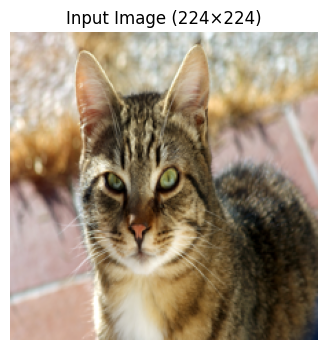

Tensor shape: torch.Size([1, 3, 224, 224])  →  (batch=1, channels=3, height=224, width=224)


In [4]:
# Standard preprocessing pipeline — must match ImageNet training conditions
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def load_image(path):
    """Load image and return both the display version (RGB) and the model tensor."""
    img_pil  = Image.open(path).convert("RGB")
    img_disp = np.array(img_pil.resize((224, 224)))  # For display
    tensor   = preprocess(img_pil).unsqueeze(0).to(device)  # (1, 3, 224, 224)
    return img_disp, tensor

# Load our test image
img_display, input_tensor = load_image("cat.jpg")

plt.figure(figsize=(4, 4))
plt.imshow(img_display)
plt.title("Input Image (224×224)")
plt.axis('off')
plt.show()
print(f"Tensor shape: {input_tensor.shape}  →  (batch=1, channels=3, height=224, width=224)")

---

## Lab 1 — Visualizing Feature Maps

We use **PyTorch forward hooks** to intercept intermediate layer outputs.  
A hook is a callback function that fires automatically when a layer runs.

```python
# Hook pattern:
def hook_fn(module, input, output):
    features.append(output)  # Capture the output tensor

layer.register_forward_hook(hook_fn)
```

We will capture activations from **three depths** in the network and compare what they detect.

In [5]:
# Feature Map Extraction via Forward Hooks

captured = {}  # Will store {layer_name: output_tensor}
hooks = []     # Keep references so we can remove them later

def make_hook(name):
    """Factory that creates a named hook function."""
    def hook_fn(module, input, output):
        captured[name] = output.detach().cpu()
    return hook_fn

# Register hooks at three different depths
hooks.append(model.layer1[0].conv1.register_forward_hook(make_hook("layer1 (shallow)")))
hooks.append(model.layer2[0].conv1.register_forward_hook(make_hook("layer2 (mid)")))
hooks.append(model.layer4[0].conv1.register_forward_hook(make_hook("layer4 (deep)")))

# Forward pass — this triggers all hooks
with torch.no_grad():
    output = model(input_tensor)

# Remove hooks (clean up — always do this!)
for h in hooks:
    h.remove()

print("Feature map shapes captured:")
for name, feat in captured.items():
    print(f"  {name}: {feat.shape}  →  ({feat.shape[1]} filters, {feat.shape[2]}×{feat.shape[3]} spatial)")

Feature map shapes captured:
  layer1 (shallow): torch.Size([1, 64, 56, 56])  →  (64 filters, 56×56 spatial)
  layer2 (mid): torch.Size([1, 128, 28, 28])  →  (128 filters, 28×28 spatial)
  layer4 (deep): torch.Size([1, 512, 7, 7])  →  (512 filters, 7×7 spatial)


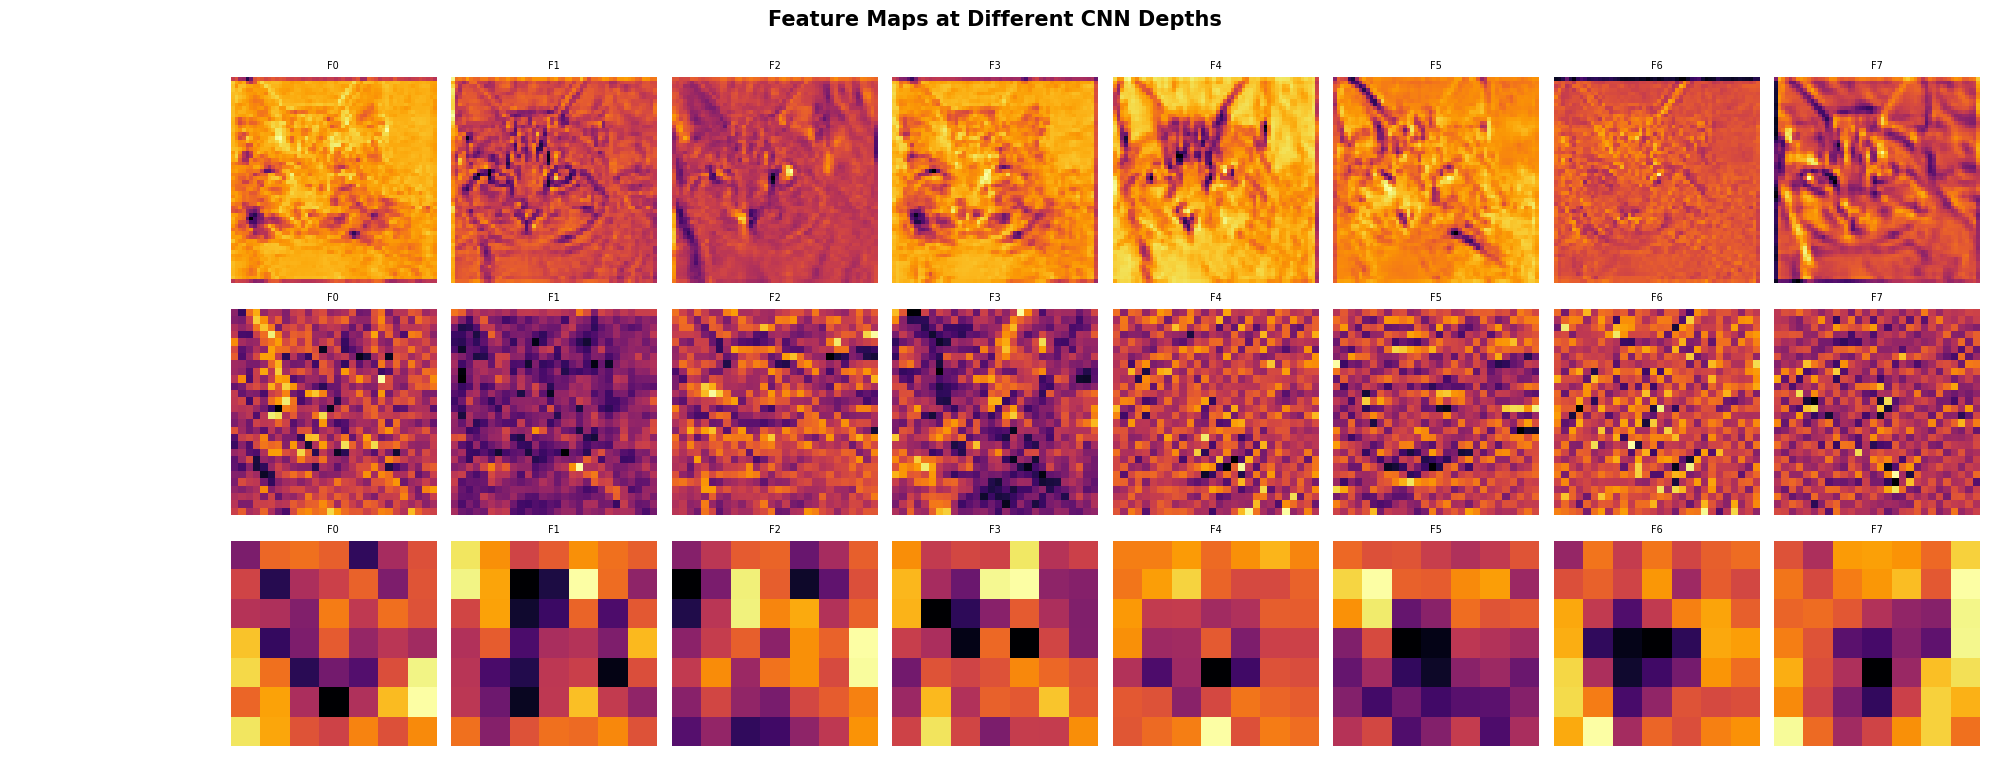


  Observations:
  • Layer 1 (shallow): High spatial detail — you can still make out the shape of the cat.
                       Filters respond to edges and simple color gradients.
  • Layer 2 (mid):     Spatial resolution drops, but pattern complexity increases.
                       Filters begin to detect textures and curves.
  • Layer 4 (deep):    Very low resolution — information is highly compressed.
                       Each activation map encodes an abstract concept, not a pixel location.



In [6]:
# Visualize 8 filters from each captured layer

def visualize_feature_maps(captured_dict, n_filters=8):
    n_layers = len(captured_dict)
    fig, axes = plt.subplots(n_layers, n_filters + 1, figsize=(20, n_layers * 2.5))
    fig.suptitle("Feature Maps at Different CNN Depths", fontsize=15, fontweight='bold', y=1.01)

    for row_idx, (layer_name, feat) in enumerate(captured_dict.items()):
        # Column 0: layer label
        axes[row_idx, 0].set_facecolor('#1a1a2e')
        axes[row_idx, 0].text(
            0.5, 0.5, layer_name.replace(" (", "\n("),
            ha='center', va='center', fontsize=9,
            color='white', fontweight='bold',
            transform=axes[row_idx, 0].transAxes
        )
        axes[row_idx, 0].axis('off')

        # Columns 1–8: individual filter activations
        for col_idx in range(n_filters):
            fmap = feat[0, col_idx].numpy()  # shape: (H, W)
            # Normalize for display
            fmap = (fmap - fmap.min()) / (fmap.max() - fmap.min() + 1e-8)
            axes[row_idx, col_idx + 1].imshow(fmap, cmap='inferno')
            axes[row_idx, col_idx + 1].set_title(f"F{col_idx}", fontsize=7)
            axes[row_idx, col_idx + 1].axis('off')

    plt.tight_layout()
    plt.show()

visualize_feature_maps(captured)

print("""
  Observations:
  • Layer 1 (shallow): High spatial detail — you can still make out the shape of the cat.
                       Filters respond to edges and simple color gradients.
  • Layer 2 (mid):     Spatial resolution drops, but pattern complexity increases.
                       Filters begin to detect textures and curves.
  • Layer 4 (deep):    Very low resolution — information is highly compressed.
                       Each activation map encodes an abstract concept, not a pixel location.
""")

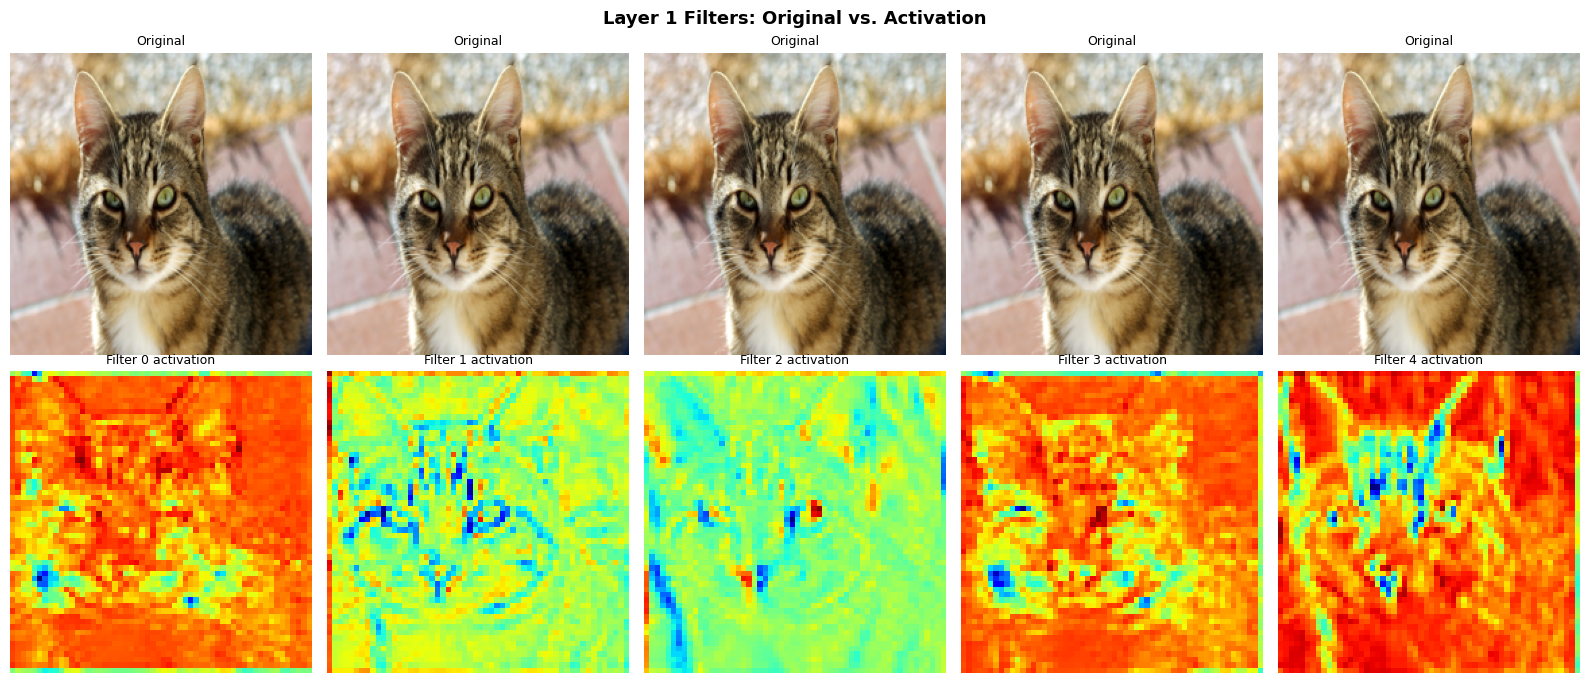

In [7]:
# Side-by-side: Original vs. Single Filter Activation
# This makes the 'what is the filter detecting?' question concrete.

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle("Layer 1 Filters: Original vs. Activation", fontsize=13, fontweight='bold')

feat_l1 = captured["layer1 (shallow)"]

for i in range(5):
    # Top row: original image
    axes[0, i].imshow(img_display)
    axes[0, i].set_title("Original", fontsize=9)
    axes[0, i].axis('off')

    # Bottom row: filter activation
    fmap = feat_l1[0, i].numpy()
    fmap = (fmap - fmap.min()) / (fmap.max() - fmap.min() + 1e-8)
    axes[1, i].imshow(fmap, cmap='jet')
    axes[1, i].set_title(f"Filter {i} activation", fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

---

# Section 2 — Grad-CAM: Why Did the Model Predict This?

Feature maps show us **what each filter activates for**, but they don't answer:

> *"For THIS specific prediction, which region of the image was most important?"*

**Grad-CAM (Gradient-weighted Class Activation Mapping)** answers that.

### How It Works (Intuition)

1. Make a prediction → get the score for class `c`
2. Backpropagate gradients to the **last convolutional layer**
3. Compute how much each feature map channel **contributed** to the prediction (average gradient)
4. Weight the feature maps by these importances and sum them
5. Upsample the result → overlay on original image as a heatmap

```
Gradient of class score
w.r.t. final conv output
        │
        ▼
  Global Average Pool  ──→  Channel weights (αᵢ)
        │
        ▼
  Weighted sum of feature maps  ──→  Grad-CAM heatmap
        │
        ▼
  ReLU + Upsample  ──→  Overlay on image
```

> **Why Grad-CAM matters:** It creates *trust* and *interpretability*. You can verify that the model is looking at the right thing — or catch it cheating.

In [8]:
# Grad-CAM Implementation (from scratch)
class GradCAM:
    """
    Grad-CAM for any CNN model.
    target_layer: the convolutional layer to extract gradients from
                  (typically the last conv layer before the classifier)
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register forward & backward hooks
        self._fwd_hook = target_layer.register_forward_hook(self._save_activation)
        self._bwd_hook = target_layer.register_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        """
        Generate Grad-CAM heatmap.
        If class_idx is None, uses the top-1 predicted class.
        Returns: heatmap (numpy, H×W, values in [0,1])
        """
        self.model.eval()

        # Forward pass
        output = self.model(input_tensor)          # (1, 1000)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        # Backward pass for the target class
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0, class_idx] = 1.0
        output.backward(gradient=one_hot)

        # Global average pooling of gradients → channel weights α
        weights = self.gradients.mean(dim=[2, 3], keepdim=True)  # (1, C, 1, 1)

        # Weighted combination of activation maps
        cam = (weights * self.activations).sum(dim=1, keepdim=True)  # (1, 1, H, W)
        cam = F.relu(cam)  # Keep only positive contributions

        # Normalize to [0, 1]
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam, class_idx

    def overlay(self, heatmap, image_np, alpha=0.5):
        """
        Overlay Grad-CAM heatmap on the original image.
        image_np: (H, W, 3) uint8 RGB
        """
        h, w = image_np.shape[:2]

        # Resize heatmap to image dimensions
        heatmap_resized = cv2.resize(heatmap, (w, h))

        # Apply colormap (jet: blue=low, red=high)
        heatmap_colored = cv2.applyColorMap(
            np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET
        )
        heatmap_rgb = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

        # Blend with original image
        blended = (alpha * heatmap_rgb + (1 - alpha) * image_np).astype(np.uint8)
        return blended

    def remove_hooks(self):
        self._fwd_hook.remove()
        self._bwd_hook.remove()


# Instantiate Grad-CAM targeting ResNet-18's last conv layer
gradcam = GradCAM(model, target_layer=model.layer4[1].conv2)
print("Grad-CAM initialized. Target layer: model.layer4[1].conv2")

Grad-CAM initialized. Target layer: model.layer4[1].conv2


---

## Lab 2 — Grad-CAM on Multiple Images

We will run Grad-CAM on three images and examine:
- **Where** the model is looking
- **What** class it predicts
- **Whether** its attention makes sense

[Cat] → Predicted: 'tabby cat' (idx=281)
[Dog] → Predicted: 'Golden Retriever' (idx=207)
[Person] → Predicted: 'suit' (idx=834)


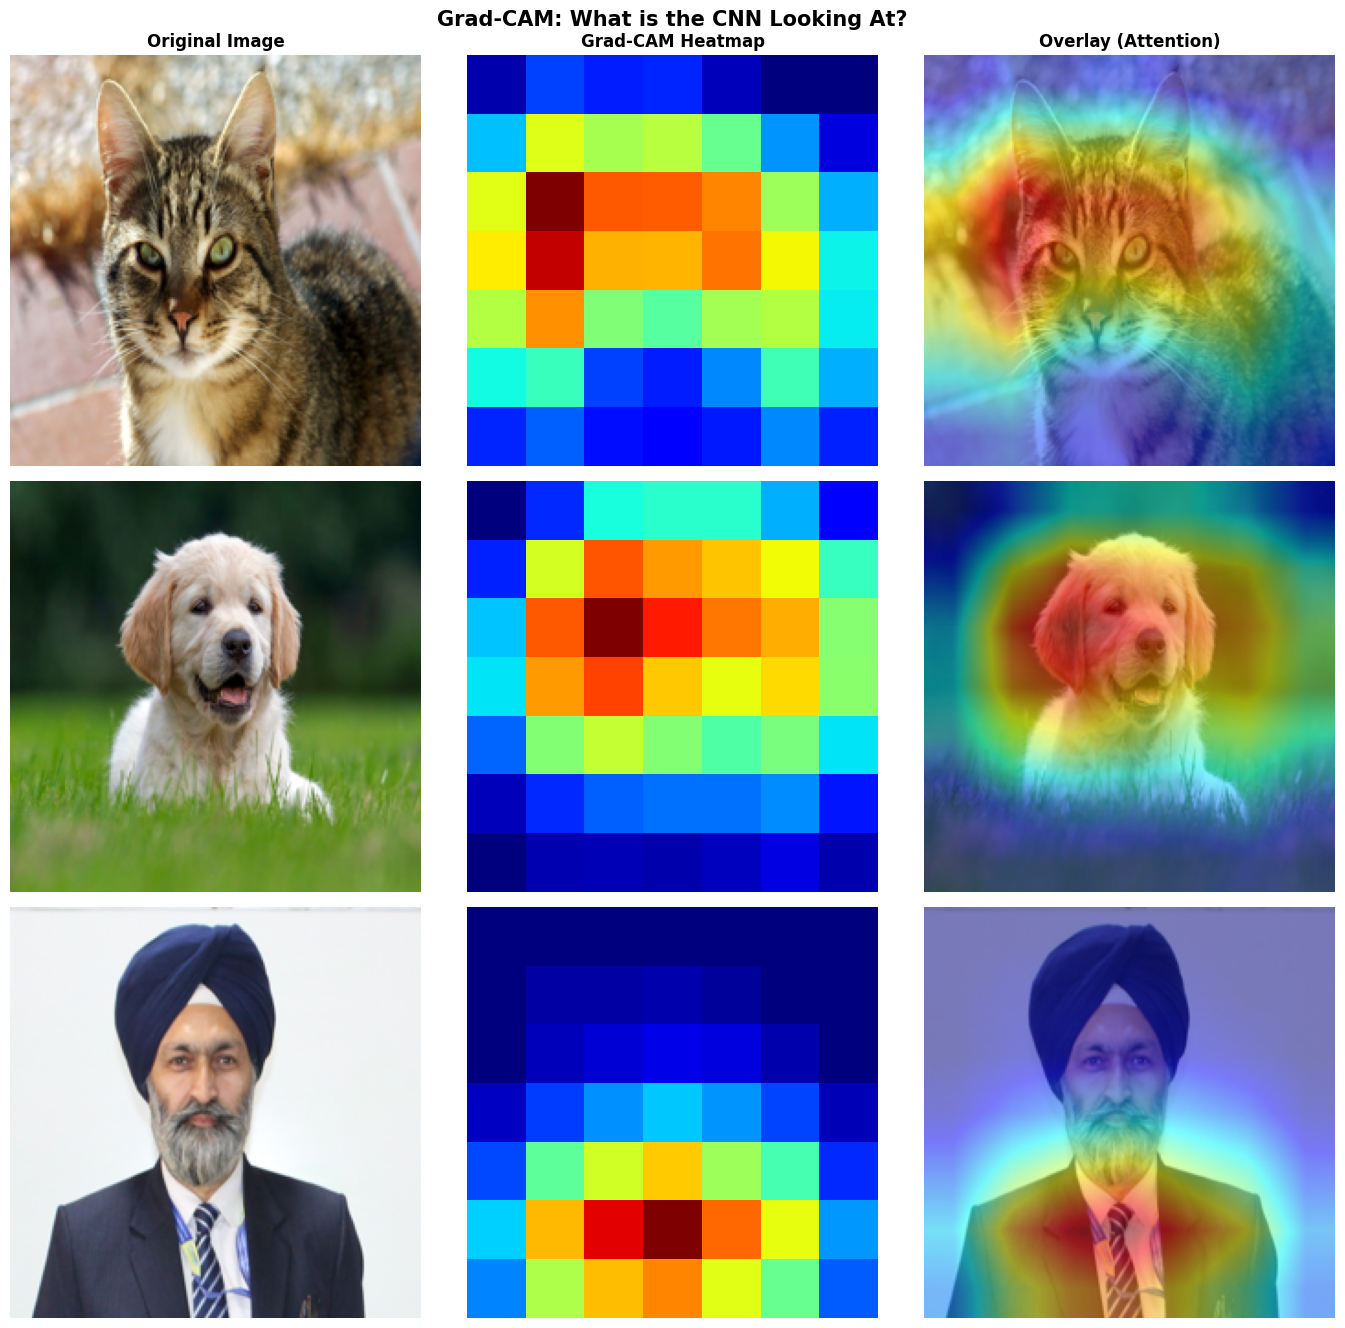

In [9]:
test_images = [
    ("cat.jpg",    "Cat"),
    ("dog.jpg",    "Dog"),
    ("person.jpg", "Person"),
]

fig, axes = plt.subplots(len(test_images), 3, figsize=(14, 4.5 * len(test_images)))
fig.suptitle("Grad-CAM: What is the CNN Looking At?", fontsize=15, fontweight='bold')

col_labels = ["Original Image", "Grad-CAM Heatmap", "Overlay (Attention)"]
for ax, label in zip(axes[0], col_labels):
    ax.set_title(label, fontsize=12, fontweight='bold')

for row_idx, (img_path, img_label) in enumerate(test_images):
    img_disp, tensor = load_image(img_path)

    # Generate Grad-CAM
    heatmap, pred_idx = gradcam.generate(tensor)
    pred_label = LABELS[pred_idx]
    overlay    = gradcam.overlay(heatmap, img_disp)

    # Column 1: Original
    axes[row_idx, 0].imshow(img_disp)
    axes[row_idx, 0].set_ylabel(f"Test: {img_label}", fontsize=10, fontweight='bold')
    axes[row_idx, 0].axis('off')

    # Column 2: Raw heatmap
    axes[row_idx, 1].imshow(heatmap, cmap='jet')
    axes[row_idx, 1].set_xlabel(f"Predicted: '{pred_label}'\n(class #{pred_idx})", fontsize=9)
    axes[row_idx, 1].axis('off')

    # Column 3: Overlay
    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].axis('off')

    print(f"[{img_label}] → Predicted: '{pred_label}' (idx={pred_idx})")

plt.tight_layout()
plt.show()

gradcam.remove_hooks()

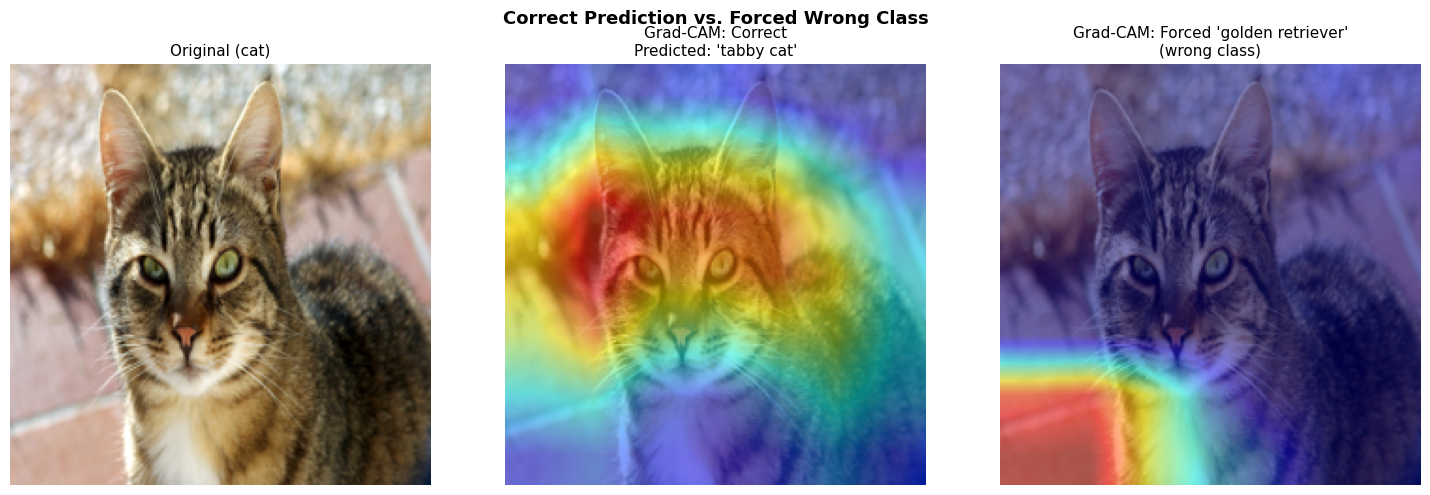


   Notice how the attention SHIFTS when we force a wrong class?
   This proves that Grad-CAM is genuinely gradient-driven — the model
   is not just highlighting the whole image. It's looking for specific
   class-discriminative regions.



In [10]:
# Bonus: Grad-CAM for a WRONG class prediction
# We can force Grad-CAM to show what regions would activate for ANY class.
# This reveals: "If the model had predicted X, where would it have looked?"

gradcam2 = GradCAM(model, target_layer=model.layer4[1].conv2)

img_disp, tensor = load_image("cat.jpg")

# Top-1 correct class
heatmap_correct, pred_idx = gradcam2.generate(tensor)
overlay_correct = gradcam2.overlay(heatmap_correct, img_disp)

# Force a wrong class: class 207 = "golden retriever" (a dog)
heatmap_wrong, _ = gradcam2.generate(tensor, class_idx=207)
overlay_wrong = gradcam2.overlay(heatmap_wrong, img_disp)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Correct Prediction vs. Forced Wrong Class", fontsize=13, fontweight='bold')

axes[0].imshow(img_disp)
axes[0].set_title("Original (cat)", fontsize=11)
axes[0].axis('off')

axes[1].imshow(overlay_correct)
axes[1].set_title(f"Grad-CAM: Correct\nPredicted: '{LABELS[pred_idx]}'", fontsize=11)
axes[1].axis('off')

axes[2].imshow(overlay_wrong)
axes[2].set_title("Grad-CAM: Forced 'golden retriever'\n(wrong class)", fontsize=11)
axes[2].axis('off')

plt.tight_layout()
plt.show()

gradcam2.remove_hooks()

print("""
   Notice how the attention SHIFTS when we force a wrong class?
   This proves that Grad-CAM is genuinely gradient-driven — the model
   is not just highlighting the whole image. It's looking for specific
   class-discriminative regions.
""")

---

# Section 3 — Failure Analysis (Critical)

A model's accuracy score tells you **how often** it's right.  
Failure analysis tells you **why** it's wrong.

These are completely different skills, and the second one matters more in production.

## Common Failure Modes in CNNs

| Failure Type | Description | Example |
|---|---|---|
| **Background bias** | Model learns background, not object | Wolf → snowy background, not wolf |
| **Texture bias** | ResNets rely on texture more than shape | Stylized cat → cat? |
| **Adversarial sensitivity** | Tiny pixel changes → wrong prediction | Panda + noise → gibbon |
| **Spurious correlation** | Model uses irrelevant features | Cow always on grass → no grass = fail |
| **Distribution shift** | Test data looks different from training | Blurry images, different lighting |

Clean image predictions:
   39.67%  tabby cat
   35.90%  tiger cat
   21.34%  Egyptian Mau
    0.42%  lynx
    0.15%  remote control


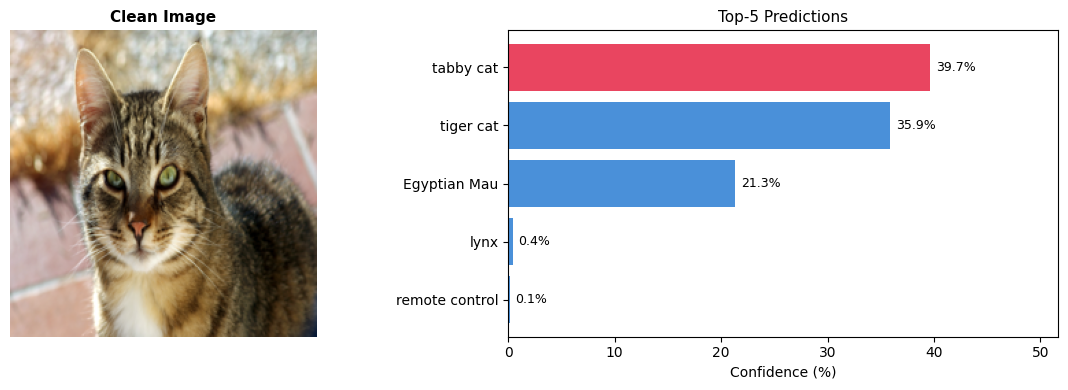

In [11]:
# Helper: Run inference and get top-5 predictions

def predict_topk(tensor, k=5):
    """Return top-k (label, confidence%) pairs."""
    with torch.no_grad():
        output = model(tensor)
    probs = F.softmax(output[0], dim=0)
    top_probs, top_idxs = probs.topk(k)
    return [(LABELS[i.item()], round(p.item() * 100, 2)) for i, p in zip(top_idxs, top_probs)]


def plot_predictions(img_disp, predictions, title="Predictions"):
    """Horizontal bar chart of top-k predictions."""
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 4))

    ax_img.imshow(img_disp)
    ax_img.set_title(title, fontsize=11, fontweight='bold')
    ax_img.axis('off')

    labels = [p[0] for p in predictions[::-1]]
    values = [p[1] for p in predictions[::-1]]
    colors = ['#e94560' if i == len(predictions) - 1 else '#4a90d9' for i in range(len(predictions))]

    bars = ax_bar.barh(labels, values, color=colors)
    ax_bar.set_xlabel("Confidence (%)")
    ax_bar.set_title("Top-5 Predictions", fontsize=11)
    for bar, val in zip(bars, values):
        ax_bar.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                    f'{val:.1f}%', va='center', fontsize=9)
    ax_bar.set_xlim(0, max(values) + 12)
    plt.tight_layout()
    plt.show()


# Baseline: clean cat prediction
img_disp, tensor = load_image("cat.jpg")
preds = predict_topk(tensor)
print("Clean image predictions:")
for label, conf in preds:
    print(f"  {conf:6.2f}%  {label}")
plot_predictions(img_disp, preds, title="Clean Image")

In [12]:
# Failure Case 1: Adding Noise (Simulating Adversarial Sensitivity)

def add_noise(tensor, noise_level=0.15):
    """Add Gaussian noise to a preprocessed image tensor."""
    noise = torch.randn_like(tensor) * noise_level
    return tensor + noise


def tensor_to_display(tensor):
    """Convert a normalized tensor back to a displayable (H,W,3) uint8 image."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img  = tensor.squeeze(0).cpu() * std + mean   # Denormalize
    img  = img.permute(1, 2, 0).clamp(0, 1).numpy()
    return (img * 255).astype(np.uint8)


img_disp, tensor = load_image("cat.jpg")

for noise_level in [0.0, 0.1, 0.3, 0.6]:
    noisy_tensor = add_noise(tensor, noise_level)
    noisy_disp   = tensor_to_display(noisy_tensor)
    preds        = predict_topk(noisy_tensor)
    top_label, top_conf = preds[0]

    status = "✅" if "cat" in top_label.lower() or "tabby" in top_label.lower() or "kitten" in top_label.lower() else "❌"
    print(f"{status} Noise={noise_level:.1f}  →  '{top_label}' ({top_conf:.1f}%)")

print("""
   Key Observation:
   As noise increases, the model's confidence drops and eventually
   it may mis-classify entirely — even though the image still looks
   like a cat to a human eye. This is the TEXTURE BIAS in action:
   the model relies heavily on fine-grained pixel statistics.
""")

✅ Noise=0.0  →  'tabby cat' (39.7%)
✅ Noise=0.1  →  'tabby cat' (42.9%)
✅ Noise=0.3  →  'tabby cat' (74.3%)
✅ Noise=0.6  →  'tabby cat' (78.4%)

   Key Observation:
   As noise increases, the model's confidence drops and eventually
   it may mis-classify entirely — even though the image still looks
   like a cat to a human eye. This is the TEXTURE BIAS in action:
   the model relies heavily on fine-grained pixel statistics.



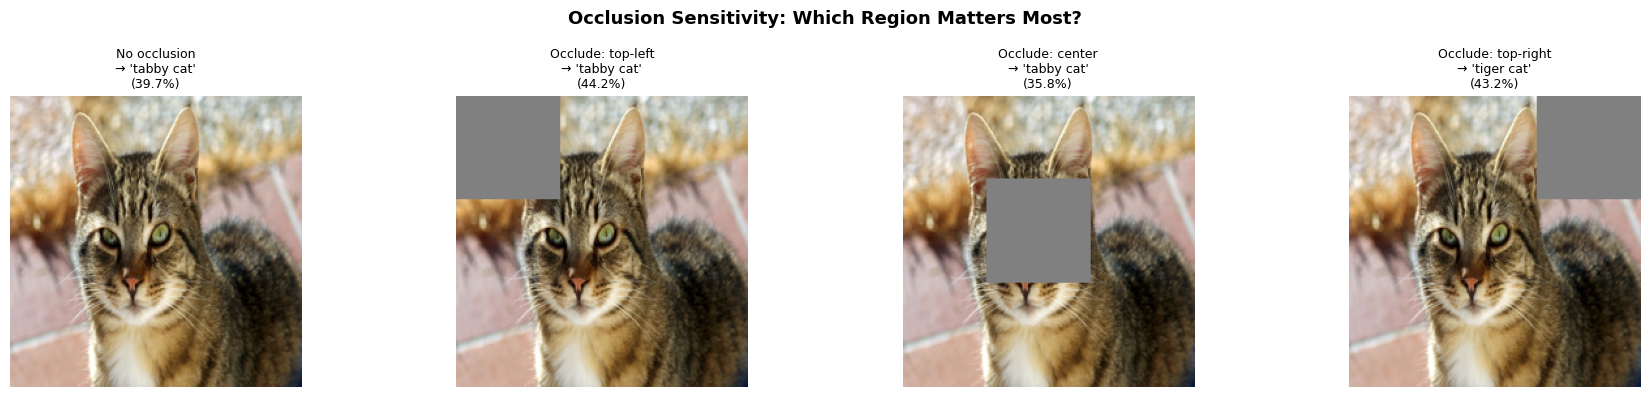


   Discussion Question:
   Which occlusion changed the prediction most drastically?
   Does this match where Grad-CAM showed the model was looking?



In [13]:
# Failure Case 2: Occlusion / Partial View
# What happens when a key region of the image is blocked?

def occlude_region(tensor, img_disp, x_start, y_start, size=60):
    """Mask a square region of the image with gray (neutral) patch."""
    t = tensor.clone()
    # In normalized space, mean ≈ 0 → gray patch
    t[0, :, y_start:y_start+size, x_start:x_start+size] = 0.0

    d = img_disp.copy()
    d[y_start:y_start+size, x_start:x_start+size] = 128  # gray
    return t, d


img_disp, tensor = load_image("cat.jpg")

occlusion_configs = [
    ("No occlusion",       tensor.clone(), img_disp.copy()),
    ("Occlude: top-left",  *occlude_region(tensor, img_disp, 0,   0,   80)),
    ("Occlude: center",    *occlude_region(tensor, img_disp, 64,  64,  80)),
    ("Occlude: top-right", *occlude_region(tensor, img_disp, 144, 0,   80)),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle("Occlusion Sensitivity: Which Region Matters Most?", fontsize=13, fontweight='bold')

for ax, (title, t, d) in zip(axes, occlusion_configs):
    preds = predict_topk(t, k=1)
    label, conf = preds[0]
    ax.imshow(d)
    ax.set_title(f"{title}\n→ '{label}'\n({conf:.1f}%)", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

print("""
   Discussion Question:
   Which occlusion changed the prediction most drastically?
   Does this match where Grad-CAM showed the model was looking?
""")

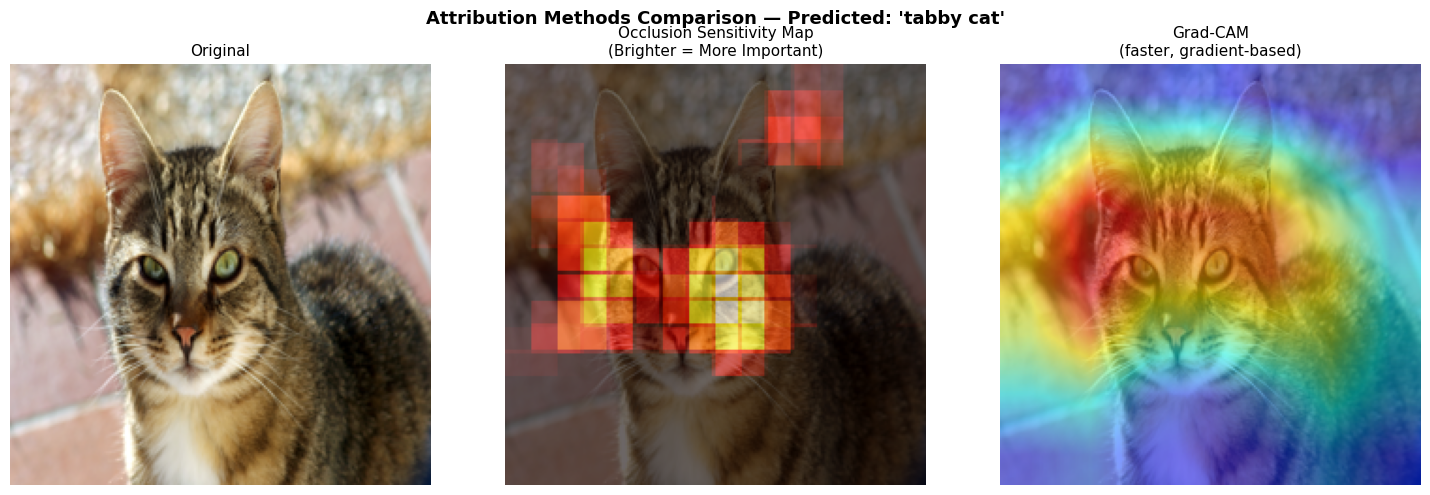

Both methods should broadly agree on WHICH regions matter — verify this!


In [14]:
# Occlusion Map + Grad-CAM Side-by-Side
# Build a full occlusion sensitivity map by sliding a patch across the image.
# SLOW for large images — we use a small stride for demonstration.

img_disp, tensor = load_image("cat.jpg")

# Baseline confidence for top class
baseline_preds = predict_topk(tensor, k=1)
baseline_label, baseline_conf = baseline_preds[0]
baseline_idx = [LABELS.index(baseline_label)][0] if baseline_label in LABELS else model(tensor).argmax().item()

# Slide a 40×40 patch across the 224×224 image with stride 14
patch_size = 40
stride     = 14
positions  = range(0, 224 - patch_size, stride)

occ_map = np.zeros((224, 224))

with torch.no_grad():
    for y in positions:
        for x in positions:
            t = tensor.clone()
            t[0, :, y:y+patch_size, x:x+patch_size] = 0.0
            prob = F.softmax(model(t)[0], dim=0)[baseline_idx].item()
            # Drop in confidence = importance of this region
            drop = baseline_conf / 100.0 - prob
            occ_map[y:y+patch_size, x:x+patch_size] += drop

occ_map = np.clip(occ_map, 0, None)
occ_map = (occ_map - occ_map.min()) / (occ_map.max() - occ_map.min() + 1e-8)

# Grad-CAM on the same image
gradcam3 = GradCAM(model, target_layer=model.layer4[1].conv2)
heatmap_gc, _ = gradcam3.generate(tensor)
gradcam3.remove_hooks()

# Side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f"Attribution Methods Comparison — Predicted: '{baseline_label}'", fontsize=13, fontweight='bold')

axes[0].imshow(img_disp)
axes[0].set_title("Original", fontsize=11)
axes[0].axis('off')

axes[1].imshow(img_disp)
axes[1].imshow(occ_map, alpha=0.6, cmap='hot')
axes[1].set_title("Occlusion Sensitivity Map\n(Brighter = More Important)", fontsize=11)
axes[1].axis('off')

axes[2].imshow(gradcam.overlay(heatmap_gc, img_disp))
axes[2].set_title("Grad-CAM\n(faster, gradient-based)", fontsize=11)
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("Both methods should broadly agree on WHICH regions matter — verify this!")

---

##  Failure Analysis Discussion Framework

When a model makes a wrong prediction, ask these questions:

### Step 1 - Get the Evidence
```python
# Run Grad-CAM on the wrong prediction
heatmap, _ = gradcam.generate(tensor, class_idx=wrong_class_idx)
overlay = gradcam.overlay(heatmap, img_display)
```

### Step 2 — Diagnose

| What you see in heatmap | Diagnosis | Fix |
|---|---|---|
| Highlighted background | Background bias | Segment objects in training data |
| Diffuse / scattered | Model is confused | More training data for this class |
| Correct region, wrong label | Similar-looking classes | Add hard negatives |
| Correct region, correct label | Model is right, label is wrong | Fix annotation error |

### Step 3 — Intervene
- Collect more data for failure cases
- Add targeted augmentation
- Fine-tune on hard examples

---

#  What's Next

---

### Task

Run the full Grad-CAM pipeline on **5 images of your choice**. At least:
- **3 images** where the model predicts correctly
- **2 images** where the model fails or behaves unexpectedly

For each image, write **5 lines** explaining:
1. What the model predicted
2. Whether the Grad-CAM attention region is reasonable
3. Your hypothesis for *why* the model succeeded or failed
4. What training change could fix a failure
5. What you found surprising

---

### Starter Code

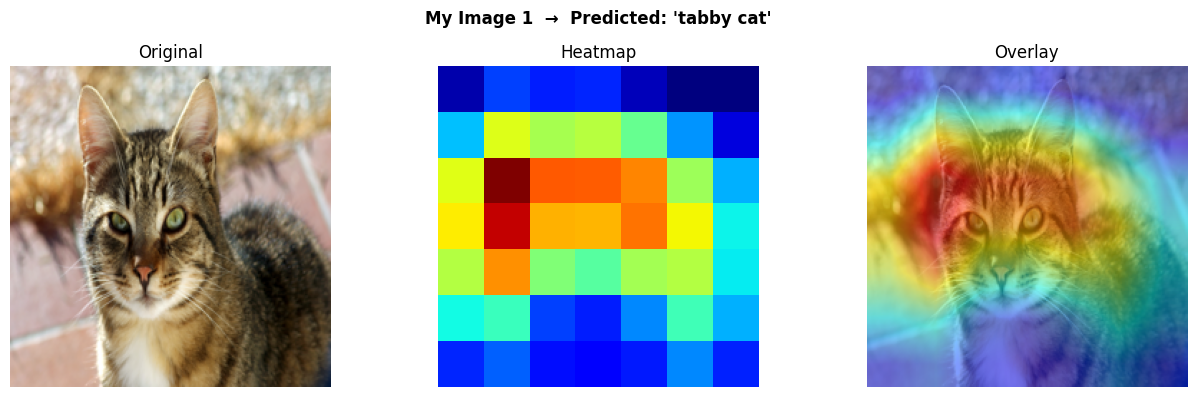


--- My Image 1 ---
Predicted: tabby cat
Your 5-line analysis:
1. [Prediction]:
2. [Attention quality]:
3. [Success/failure hypothesis]:
4. [Proposed fix]:
5. [Surprise]:



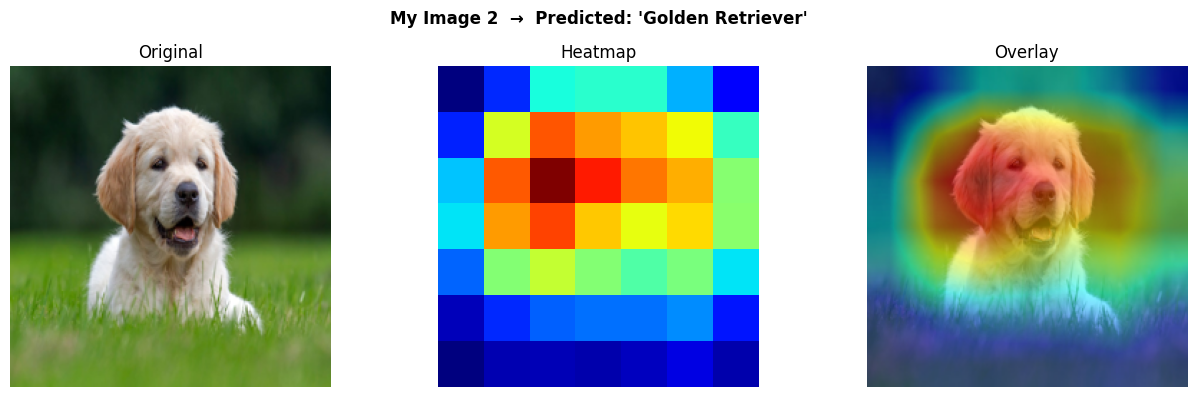


--- My Image 2 ---
Predicted: Golden Retriever
Your 5-line analysis:
1. [Prediction]:
2. [Attention quality]:
3. [Success/failure hypothesis]:
4. [Proposed fix]:
5. [Surprise]:



In [15]:
# ASSIGNMENT STARTER
# Replace the image URLs below with your own choices.
# You can also upload images directly to Colab and use local paths.

MY_IMAGES = [
    # (url_or_path, your_label)
    ("cat.jpg",    "My Image 1"),
    ("dog.jpg",    "My Image 2"),
    # Add 3 more images here:
    # ("https://...", "My Image 3"),
    # ("https://...", "My Image 4"),
    # ("https://...", "My Image 5"),
]

# Download remote images if needed
for path_or_url, label in MY_IMAGES:
    if path_or_url.startswith("http"):
        filename = label.replace(" ", "_") + ".jpg"
        urllib.request.urlretrieve(path_or_url, filename)
        print(f"Downloaded: {filename}")

# ─── Run Grad-CAM on all your images ─────────────────────────────────────────
gradcam_assign = GradCAM(model, target_layer=model.layer4[1].conv2)

for img_path, my_label in MY_IMAGES:
    if img_path.startswith("http"):
        img_path = my_label.replace(" ", "_") + ".jpg"

    img_disp, tensor = load_image(img_path)
    heatmap, pred_idx = gradcam_assign.generate(tensor)
    overlay = gradcam_assign.overlay(heatmap, img_disp)
    pred_label = LABELS[pred_idx]

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    fig.suptitle(f"{my_label}  →  Predicted: '{pred_label}'", fontsize=12, fontweight='bold')

    axes[0].imshow(img_disp);  axes[0].set_title("Original");    axes[0].axis('off')
    axes[1].imshow(heatmap, cmap='jet');  axes[1].set_title("Heatmap");  axes[1].axis('off')
    axes[2].imshow(overlay);   axes[2].set_title("Overlay");    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"\n--- {my_label} ---")
    print(f"Predicted: {pred_label}")
    print("Your 5-line analysis:")
    print("1. [Prediction]:")
    print("2. [Attention quality]:")
    print("3. [Success/failure hypothesis]:")
    print("4. [Proposed fix]:")
    print("5. [Surprise]:")
    print()

gradcam_assign.remove_hooks()

---

#  Lecture Summary

| Concept | What You Learned |
|---|---|
| **CNN Hierarchy** | Early layers = edges/textures, Deep layers = object concepts |
| **Forward Hooks** | How to intercept intermediate layer outputs in PyTorch |
| **Feature Map Visualization** | Directly observing what each filter detects |
| **Grad-CAM** | Gradient-based class-discriminative spatial attention |
| **Failure Analysis** | Diagnosing wrong predictions using attribution maps |
| **Occlusion Sensitivity** | Brute-force alternative to Grad-CAM |

---

##  Mental Model Upgrade

```
BEFORE  →  "The model predicted 'cat' with 94% confidence."

AFTER   →  "The model predicted 'cat' because it focused on the ear
            shape and eye region. When the center is occluded, confidence
            drops to 31% — suggesting it relies on the face, not the fur
            texture. This is correct reasoning."
```

---